In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
from matplotlib import pyplot as plt

In [ ]:
tas_z = xr.open_dataset("../data/features/tas_z.nc")
smtop_z = xr.open_dataset("../data/features/smtop_z.nc")
smmid_z = xr.open_dataset("../data/features/smmid_z.nc")
smlow_z = xr.open_dataset("../data/features/smlow_z.nc")
pr_z = xr.open_dataset("../data/features/pr_z.nc")
dtr_z = xr.open_dataset("../data/features/dtr_z.nc")

In [23]:
# load feature ds
feature_ds = xr.open_dataset("../data/features/feature_ds.nc").load()

In [4]:
tas_z.var

<bound method DatasetAggregations.var of <xarray.Dataset> Size: 570kB
Dimensions:    (region_id: 79, year: 25, month: 12, dekad: 3)
Coordinates:
  * region_id  (region_id) int64 632B 1 2 3 4 5 6 7 8 ... 73 74 75 76 77 78 79
  * year       (year) int32 100B 2001 2002 2003 2004 ... 2022 2023 2024 2025
  * month      (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * dekad      (dekad) int64 24B 1 2 3
Data variables:
    tas_z      (region_id, year, month, dekad) float64 569kB ...>

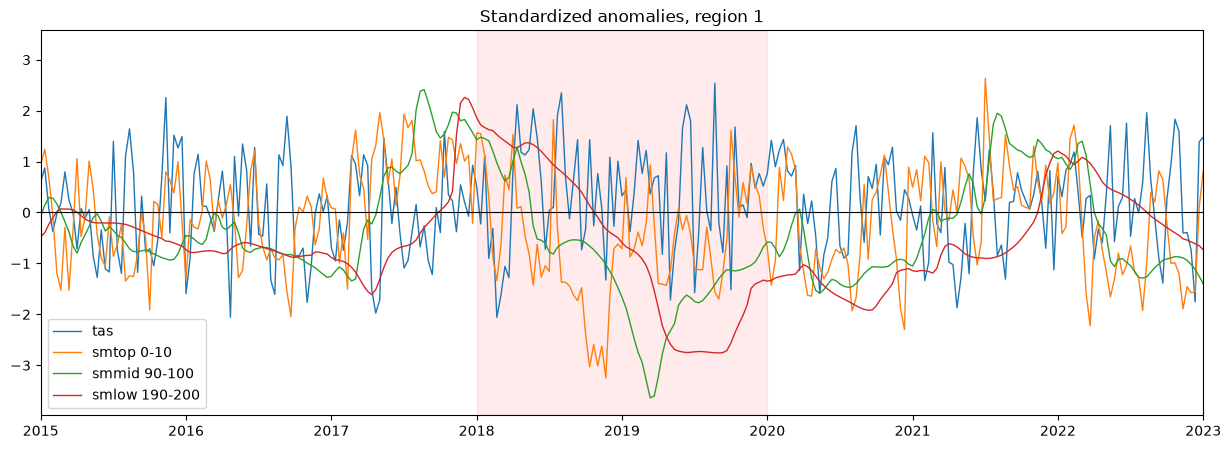

In [ ]:

# plot from ChatGPT 
def to_series(da, rid):
    selected = da.sel(region_id=rid)

    if isinstance(selected, xr.Dataset):
        # If it's a Dataset, select the variable to plot
        if len(selected.data_vars) == 1:
            selected = selected[next(iter(selected.data_vars))]
        else:
            raise ValueError(
                f"Expected one variable, found: {list(selected.data_vars)}"
            )

    df = selected.to_dataframe(name="z").reset_index()

    df["t"] = (
        df["year"]
        + (df["month"] - 1) / 12
        + (df["dekad"] - 1) / 36
    )

    return df.sort_values("t")


rid = 1

fig, ax = plt.subplots(figsize=(15, 5))

for da, label in [
    (tas_z, "tas"),
    (smtop_z, "smtop 0-10"),
    (smmid_z, "smmid 90-100"),
    (smlow_z, "smlow 190-200"),
]:
    s = to_series(da, rid)
    ax.plot(s["t"], s["z"], label=label, lw=1)

ax.axhline(0, color="k", lw=0.8)
ax.axvspan(2018, 2020, color="red", alpha=0.08)
ax.set_xlim(2015, 2023)
ax.legend()
ax.set_title(f"Standardized anomalies, region {rid}")

plt.show()

In [9]:
z = smtop_z.stack(t=("year", "month", "dekad"))
print(z.sel(region_id=1).idxmin("t").values)   # most negative dekad for region 1

<bound method Mapping.values of <xarray.Dataset> Size: 24B
Dimensions:              ()
Coordinates:
    transverse_mercator  int64 8B 0
    region_id            int64 8B 1
Data variables:
    smtop_z              object 8B (2018, 11, 3)>


In [22]:
# check pearson correlation 
rid = 1

df = pd.DataFrame({
    "tas": tas_z.sel(region_id=rid).to_dataframe()["tas_z"].values,
    "dtr": dtr_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,
    "smtop": smtop_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,
    "smmid": smmid_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,
    "smlow": smlow_z.sel(region_id=rid).to_dataframe().iloc[:, 0].values,

})

print(df.corr().round(2))

        tas   dtr  smtop  smmid  smlow
tas    1.00  0.33  -0.14  -0.15  -0.08
dtr    0.33  1.00  -0.45  -0.15  -0.04
smtop -0.14 -0.45   1.00   0.38   0.13
smmid -0.15 -0.15   0.38   1.00   0.65
smlow -0.08 -0.04   0.13   0.65   1.00


1


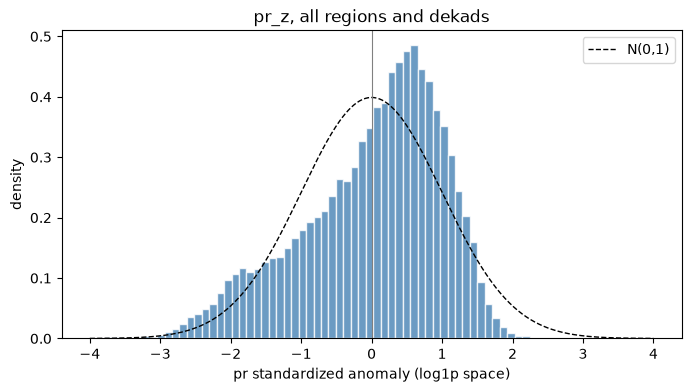

n = 71100, min = -3.89, max = 2.45
skewness = -0.68


In [ ]:
# check histogramm for standardized pr
# confirm log1p transform improved skew

# code by ChatGPT
z = pr_z["pr_z"]

vals = z.values.ravel()
vals = vals[np.isfinite(vals)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vals, bins=60, density=True, color="steelblue", alpha=0.8, edgecolor="white")

# reference: standard normal curve
x = np.linspace(-4, 4, 400)
ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="N(0,1)")

ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("pr standardized anomaly (log1p space)")
ax.set_ylabel("density")
ax.set_title("pr_z, all regions and dekads")
ax.legend()
plt.show()

print(f"n = {vals.size}, min = {vals.min():.2f}, max = {vals.max():.2f}")
print(f"skewness = {((vals - vals.mean())**3).mean() / vals.std()**3:.2f}")

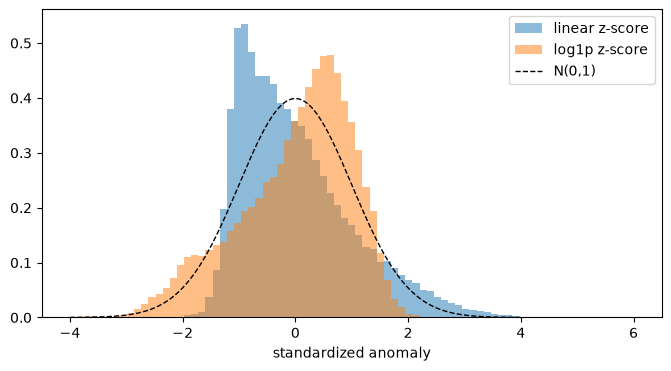

n = 71100, min = 0.00, max = 179.61
skewness = 2.11


In [19]:
# compare to untransformed raw pr values
# code for plot by ChatGPT
pr_dek = xr.open_dataarray("../data/processed/pr_sum_dekadal_natraum_2001_2025.nc")
mu = pr_dek.mean("year")
sd = pr_dek.std("year", ddof=0)
z_lin = ((pr_dek - mu) / sd).values.ravel()
z_lin = z_lin[np.isfinite(z_lin)]

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(-4, 6, 80)
ax.hist(z_lin, bins=bins, density=True, alpha=0.5, label="linear z-score")
ax.hist(vals, bins=bins, density=True, alpha=0.5, label="log1p z-score")
ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="N(0,1)")
ax.legend()
ax.set_xlabel("standardized anomaly")
plt.show()

vals = pr_dek.values.ravel()
vals = vals[np.isfinite(vals)]

print(f"n = {vals.size}, min = {vals.min():.2f}, max = {vals.max():.2f}")
print(f"skewness = {((vals - vals.mean())**3).mean() / vals.std()**3:.2f}")

In [18]:
z = pr_z["pr_z"]
extreme = z.where(z < -3)

# count of extreme-dry cells per month
print(extreme.notnull().sum(dim=["region_id", "year", "dekad"]).to_series())

# and which years
print(extreme.notnull().sum(dim=["region_id", "month", "dekad"]).to_series())

month
1     114
2       0
3       0
4       0
5       6
6      13
7       8
8       4
9       0
10     10
11      0
12      1
Name: pr_z, dtype: int64
year
2001      0
2002      2
2003      1
2004      1
2005      0
2006    114
2007      1
2008      0
2009      0
2010     10
2011      0
2012      0
2013      2
2014      2
2015      0
2016      0
2017      0
2018     11
2019      1
2020      0
2021      1
2022      4
2023      6
2024      0
2025      0
Name: pr_z, dtype: int64


In [21]:
dtr_z.var

<bound method DatasetAggregations.var of <xarray.Dataset> Size: 570kB
Dimensions:    (region_id: 79, year: 25, month: 12, dekad: 3)
Coordinates:
  * region_id  (region_id) int64 632B 1 2 3 4 5 6 7 8 ... 73 74 75 76 77 78 79
  * year       (year) int32 100B 2001 2002 2003 2004 ... 2022 2023 2024 2025
  * month      (month) int32 48B 1 2 3 4 5 6 7 8 9 10 11 12
  * dekad      (dekad) int64 24B 1 2 3
Data variables:
    dtr_z      (region_id, year, month, dekad) float64 569kB ...>

## Correlation analysis between features

In [ ]:
feat_cols = list(feature_ds.data_vars)

ml_df = feature_ds.to_dataframe().reset_index().dropna(subset=feat_cols).reset_index(drop=True)
X = ml_df[feat_cols]
print(X.shape)    # looks right!

(70863, 9)


In [29]:
corr = X.corr()                      # Pearson correlation
print(corr)


                   pr_z  pr3dek_z  drydays_z     tas_z     dtr_z   smtop_z  \
pr_z           1.000000  0.552036  -0.828797 -0.066344 -0.453978  0.532581   
pr3dek_z       0.552036  1.000000  -0.488052 -0.095100 -0.390802  0.755573   
drydays_z     -0.828797 -0.488052   1.000000  0.108496  0.467002 -0.497189   
tas_z         -0.066344 -0.095100   0.108496  1.000000  0.361099 -0.176282   
dtr_z         -0.453978 -0.390802   0.467002  0.361099  1.000000 -0.474132   
smtop_z        0.532581  0.755573  -0.497189 -0.176282 -0.474132  1.000000   
smtop_trend_z  0.492554  0.660141  -0.459275 -0.081814 -0.375138  0.557163   
smmid_z        0.018203  0.179099  -0.024598 -0.147061 -0.149203  0.403217   
smlow_z       -0.004926  0.019954   0.003040 -0.092113 -0.061032  0.152172   

               smtop_trend_z   smmid_z   smlow_z  
pr_z                0.492554  0.018203 -0.004926  
pr3dek_z            0.660141  0.179099  0.019954  
drydays_z          -0.459275 -0.024598  0.003040  
tas_z          

In [ ]:
corr_s = X.corr(method="spearman")   # robust to the skew in the precipitation features
print(corr_s)

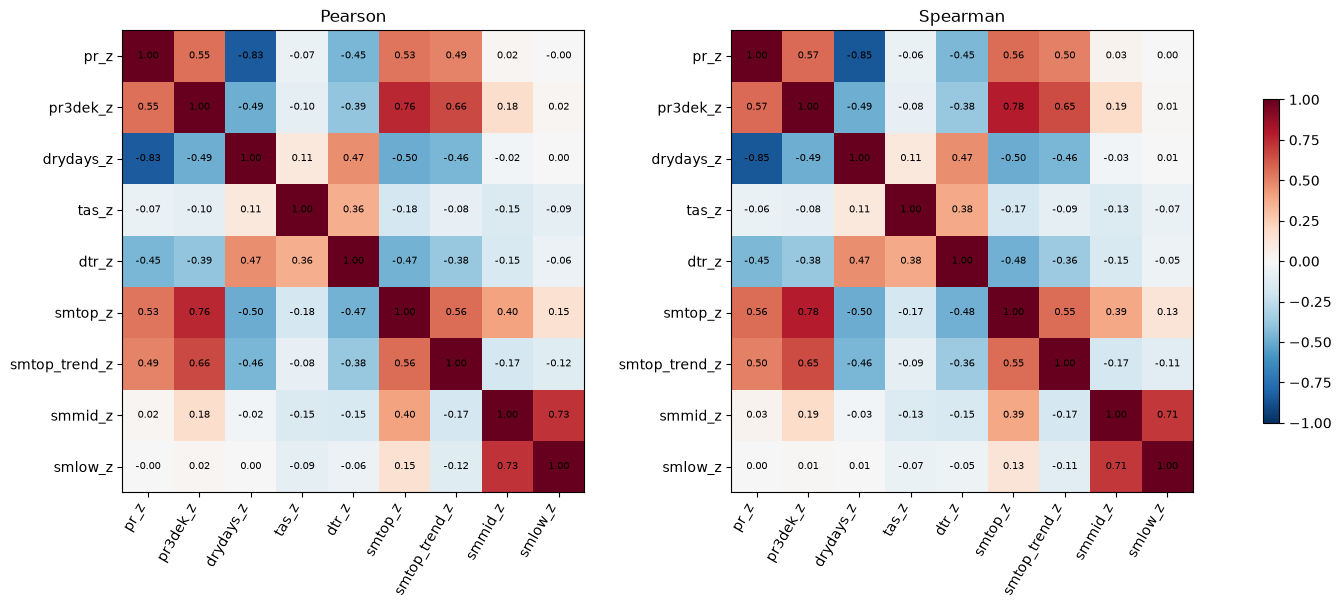

   feature_1  feature_2         r
2       pr_z  drydays_z -0.828797
14  pr3dek_z    smtop_z  0.755573
71   smmid_z    smlow_z  0.725363


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, c, title in zip(axes, [corr, corr_s], ["Pearson", "Spearman"]):
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(feat_cols)), feat_cols, rotation=60, ha="right")
    ax.set_yticks(range(len(feat_cols)), feat_cols)
    for i in range(len(feat_cols)):
        for j in range(len(feat_cols)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

# flag the strong pairs
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
         .stack().rename("r").reset_index())
pairs.columns = ["feature_1", "feature_2", "r"]
print(pairs[pairs["r"].abs() > 0.7].sort_values("r", key=abs, ascending=False))

In [34]:
# corr of just summer months
summer = ml_df[ml_df["month"].between(5, 9)]
print(summer[feat_cols].corr().round(2))

               pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  \
pr_z           1.00      0.54      -0.80  -0.31  -0.59     0.51   
pr3dek_z       0.54      1.00      -0.48  -0.32  -0.51     0.79   
drydays_z     -0.80     -0.48       1.00   0.41   0.64    -0.47   
tas_z         -0.31     -0.32       0.41   1.00   0.62    -0.40   
dtr_z         -0.59     -0.51       0.64   0.62   1.00    -0.62   
smtop_z        0.51      0.79      -0.47  -0.40  -0.62     1.00   
smtop_trend_z  0.47      0.68      -0.44  -0.32  -0.48     0.62   
smmid_z        0.05      0.24      -0.05  -0.11  -0.23     0.50   
smlow_z        0.01      0.03      -0.01  -0.01  -0.11     0.16   

               smtop_trend_z  smmid_z  smlow_z  
pr_z                    0.47     0.05     0.01  
pr3dek_z                0.68     0.24     0.03  
drydays_z              -0.44    -0.05    -0.01  
tas_z                  -0.32    -0.11    -0.01  
dtr_z                  -0.48    -0.23    -0.11  
smtop_z                 0.62     0.

## PCA

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

   PC  explained  cumulative
0   1      0.418       0.418
1   2      0.209       0.626
2   3      0.119       0.745
3   4      0.092       0.837
4   5      0.055       0.892
5   6      0.050       0.942
6   7      0.025       0.967
7   8      0.018       0.985
8   9      0.015       1.000


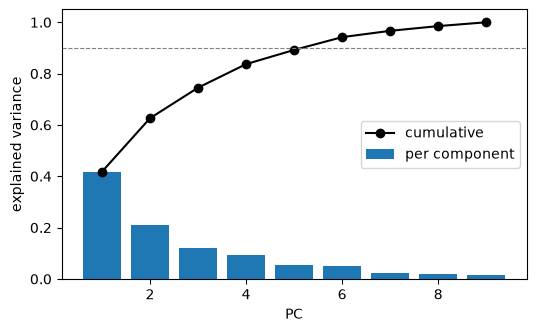

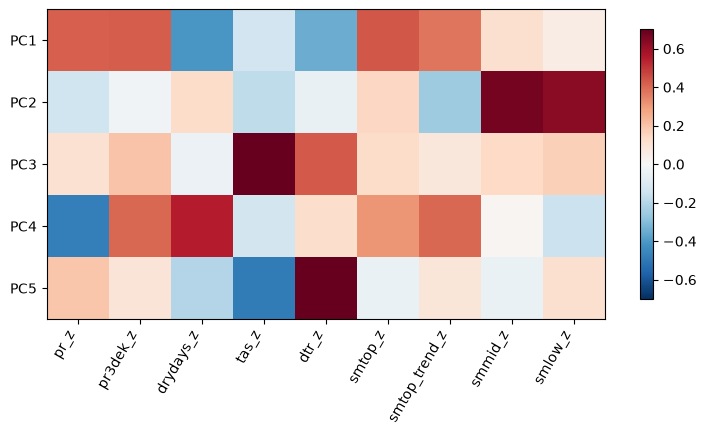

     pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  smmid_z  \
PC1  0.42      0.42      -0.41  -0.13  -0.35     0.43           0.37     0.11   
PC2 -0.14     -0.03       0.13  -0.18  -0.05     0.14          -0.25     0.67   
PC3  0.11      0.20      -0.04   0.83   0.43     0.13           0.08     0.14   
PC4 -0.48      0.40       0.55  -0.13   0.13     0.31           0.40     0.01   
PC5  0.19      0.09      -0.20  -0.49   0.81    -0.04           0.09    -0.05   
PC6 -0.05     -0.18       0.04   0.04  -0.12    -0.37           0.63    -0.27   

     smlow_z  
PC1     0.05  
PC2     0.63  
PC3     0.16  
PC4    -0.15  
PC5     0.11  
PC6     0.59  


In [39]:
Xs = StandardScaler().fit_transform(X)       # almost a no-op, features are already z-scores
pca = PCA().fit(Xs)

evr = pca.explained_variance_ratio_
print(pd.DataFrame({"PC": range(1, len(evr) + 1),
                    "explained": evr.round(3),
                    "cumulative": evr.cumsum().round(3)}))

# scree plot
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(range(1, len(evr) + 1), evr, label="per component")
ax.plot(range(1, len(evr) + 1), evr.cumsum(), "ko-", label="cumulative")
ax.axhline(0.9, color="grey", ls="--", lw=0.8)
ax.set_xlabel("PC"); ax.set_ylabel("explained variance"); ax.legend()
plt.show()

# loadings, one row per PC
loadings = pd.DataFrame(pca.components_, columns=feat_cols,
                        index=[f"PC{i+1}" for i in range(len(feat_cols))])
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(loadings.iloc[:5], cmap="RdBu_r", vmin=-0.7, vmax=0.7)    # first 5 PCs
ax.set_xticks(range(len(feat_cols)), feat_cols, rotation=60, ha="right")
ax.set_yticks(range(5), loadings.index[:5])
fig.colorbar(im, shrink=0.7)
plt.show()
print(loadings.iloc[:6].round(2))

In [51]:
k = 6
load_k = pca.components_[:k].T * np.sqrt(pca.explained_variance_[:k])   # shape (9 features, k)
retained = pd.Series((load_k**2).sum(axis=1), index=feat_cols).round(2)
print(retained.sort_values())

pr3dek_z         0.87
smtop_z          0.90
pr_z             0.91
drydays_z        0.92
smmid_z          0.94
smtop_trend_z    0.96
smlow_z          0.97
tas_z            1.00
dtr_z            1.00
dtype: float64


In [52]:
print(loadings.iloc[4:6].round(2))   # PC5 and PC6

     pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  smmid_z  \
PC5  0.19      0.09      -0.20  -0.49   0.81    -0.04           0.09    -0.05   
PC6 -0.05     -0.18       0.04   0.04  -0.12    -0.37           0.63    -0.27   

     smlow_z  
PC5     0.11  
PC6     0.59  


## Cluster Finding

In [56]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

k=2 done
k=3 done
k=4 done
k=5 done
k=6 done
k=7 done
k=8 done
k=9 done
k=10 done
k=2 done
k=3 done
k=4 done
k=5 done
k=6 done
k=7 done
k=8 done
k=9 done
k=10 done


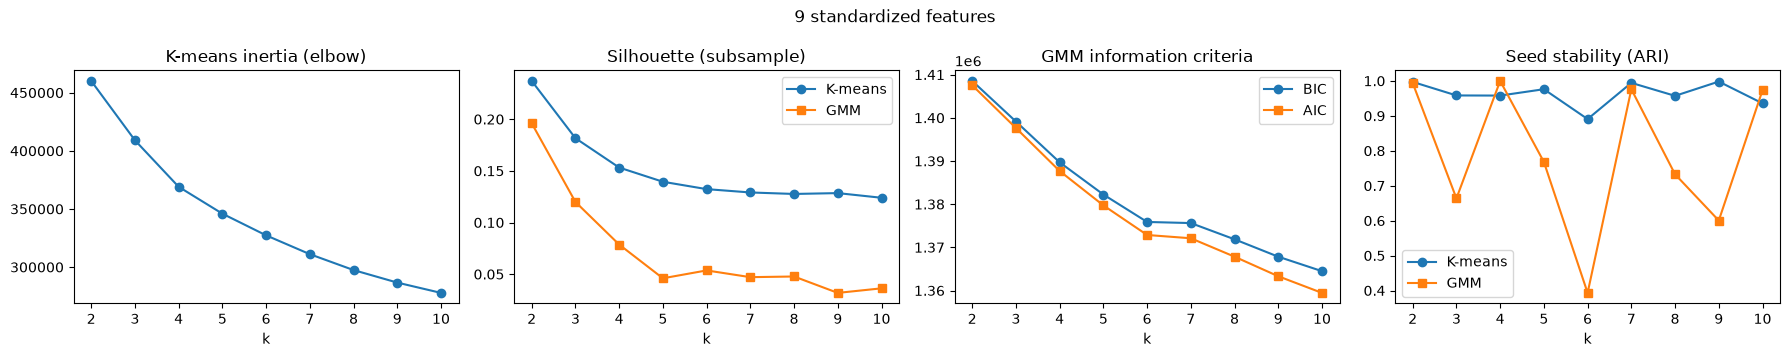

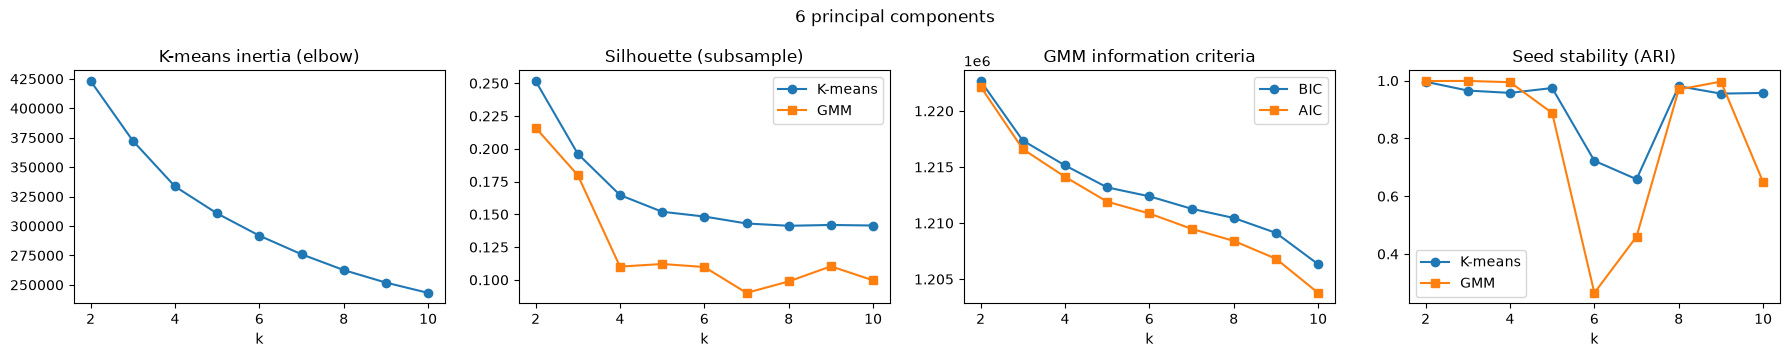

    km_inertia  km_silhouette  km_davies_bouldin  km_stability_ari  \
k                                                                    
2   460101.905          0.237              1.533             0.997   
3   409052.278          0.182              1.753             0.958   
4   369034.770          0.153              1.682             0.958   
5   345925.863          0.139              1.771             0.976   
6   327290.194          0.132              1.736             0.891   
7   311087.954          0.129              1.720             0.994   
8   297424.279          0.128              1.688             0.957   
9   286645.584          0.128              1.675             0.998   
10  277785.848          0.124              1.676             0.936   

    km_min_share      gmm_bic      gmm_aic  gmm_silhouette  gmm_stability_ari  \
k                                                                               
2          0.472  1408542.697  1407543.330           0.196         

In [58]:
Xs  = StandardScaler().fit_transform(X)        # 9 standardized features (primary)
Z6  = pca.transform(Xs)[:, :6]                 # 6 PC scores (robustness run), no whitening

def evaluate_k(X, k_range=range(2, 11), sample_size=10000, seed=42):
    """
    For each k: K-means (inertia, silhouette on a subsample, Davies-Bouldin, seed stability,
    smallest cluster share) and GMM with full covariance (BIC, AIC, silhouette on the same subsample).
    Stability = adjusted Rand index between two fits with different random seeds.
    """
    rows = []
    for k in k_range:
        km  = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        km2 = KMeans(n_clusters=k, n_init=10, random_state=seed + 1).fit(X)

        gmm  = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=seed).fit(X)
        gmm2 = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=seed + 1).fit(X)
        gl, gl2 = gmm.predict(X), gmm2.predict(X)

        rows.append({
            "k": k,
            "km_inertia": km.inertia_,
            "km_silhouette": silhouette_score(X, km.labels_, sample_size=sample_size, random_state=seed),
            "km_davies_bouldin": davies_bouldin_score(X, km.labels_),
            "km_stability_ari": adjusted_rand_score(km.labels_, km2.labels_),
            "km_min_share": np.bincount(km.labels_).min() / len(X),
            "gmm_bic": gmm.bic(X),
            "gmm_aic": gmm.aic(X),
            "gmm_silhouette": silhouette_score(X, gl, sample_size=sample_size, random_state=seed),
            "gmm_stability_ari": adjusted_rand_score(gl, gl2),
            "gmm_min_share": np.bincount(gl, minlength=k).min() / len(X),
        })
        print(f"k={k} done")
    return pd.DataFrame(rows).set_index("k")


def plot_k_selection(res, title):
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    axes[0].plot(res.index, res["km_inertia"], "o-");                  axes[0].set_title("K-means inertia (elbow)")
    axes[1].plot(res.index, res["km_silhouette"], "o-", label="K-means")
    axes[1].plot(res.index, res["gmm_silhouette"], "s-", label="GMM"); axes[1].set_title("Silhouette (subsample)"); axes[1].legend()
    axes[2].plot(res.index, res["gmm_bic"], "o-", label="BIC")
    axes[2].plot(res.index, res["gmm_aic"], "s-", label="AIC");       axes[2].set_title("GMM information criteria"); axes[2].legend()
    axes[3].plot(res.index, res["km_stability_ari"], "o-", label="K-means")
    axes[3].plot(res.index, res["gmm_stability_ari"], "s-", label="GMM"); axes[3].set_title("Seed stability (ARI)"); axes[3].legend()
    for ax in axes: ax.set_xlabel("k")
    fig.suptitle(title); plt.tight_layout(); plt.show()


res9 = evaluate_k(Xs)
res6 = evaluate_k(Z6)
plot_k_selection(res9, "9 standardized features")
plot_k_selection(res6, "6 principal components")
print(res9.round(3)); print(res6.round(3))

## Fit Testing / Final Fit

In [59]:
from scipy.optimize import linear_sum_assignment

### K = 4

In [60]:
K = 4

# profiling and run lengths need chronological order within each region
ml_df = ml_df.sort_values(["region_id", "year", "month", "dekad"]).reset_index(drop=True)
assert len(ml_df) == len(Xs), "ml_df and Xs must have the same row order, rebuild Xs/Z6 from the sorted frame"

def reorder_by_wetness(labels, df, cols=("pr3dek_z", "smtop_z", "smmid_z")):
    """Relabel clusters so 0 = driest ... k-1 = wettest (mean of the three wetness features)."""
    wet = df[list(cols)].mean(axis=1).values
    order = pd.Series(wet).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[l] for l in labels])

def fit_models(X, k, df, seed=42):
    km = KMeans(n_clusters=k, n_init=50, random_state=seed).fit(X)
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=20,
                          max_iter=500, random_state=seed).fit(X)
    print(f"GMM converged: {gmm.converged_}, log-likelihood lower bound: {gmm.lower_bound_:.4f}")
    km_lab = reorder_by_wetness(km.labels_, df)
    gmm_lab = reorder_by_wetness(gmm.predict(X), df)
    return km, gmm, km_lab, gmm_lab

km9, gmm9, ml_df["km_label"], ml_df["gmm_label"] = fit_models(Xs, K, ml_df)
km6, gmm6, ml_df["km_label_pc"], ml_df["gmm_label_pc"] = fit_models(Z6, K, ml_df)

# GMM posterior: how "soft" is the assignment?
post = gmm9.predict_proba(Xs)
ml_df["gmm_maxprob"] = post.max(axis=1)

# robustness: 9 features vs 6 PCs
print("ARI KM 9feat vs 6PC :", round(adjusted_rand_score(ml_df["km_label"], ml_df["km_label_pc"]), 3))
print("ARI GMM 9feat vs 6PC:", round(adjusted_rand_score(ml_df["gmm_label"], ml_df["gmm_label_pc"]), 3))

GMM converged: True, log-likelihood lower bound: -9.7888
GMM converged: True, log-likelihood lower bound: -8.5652
ARI KM 9feat vs 6PC : 0.912
ARI GMM 9feat vs 6PC: 0.347


   share  mean_run_dekads  median_run_dekads
0   0.22             1.73                1.0
1   0.30             2.06                1.0
2   0.22             2.56                2.0
3   0.26             1.94                1.0
          pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  \
km_label                                                                    
0        -1.25     -1.15       1.07   0.34   0.94    -1.01          -0.94   
1         0.07     -0.09       0.06   0.14   0.14    -0.43          -0.00   
2         0.08      0.23       0.04  -0.26  -0.25     0.42          -0.26   
3         0.91      0.88      -1.01  -0.22  -0.73     0.99           1.01   

          smmid_z  smlow_z  
km_label                    
0           -0.11     0.05  
1           -0.70    -0.63  
2            1.08     0.99  
3           -0.03    -0.17  


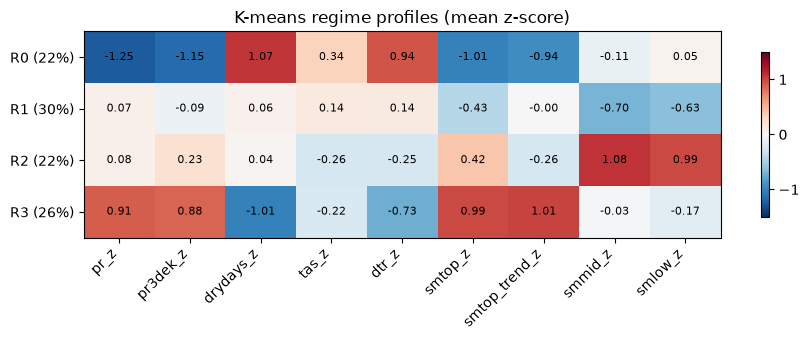

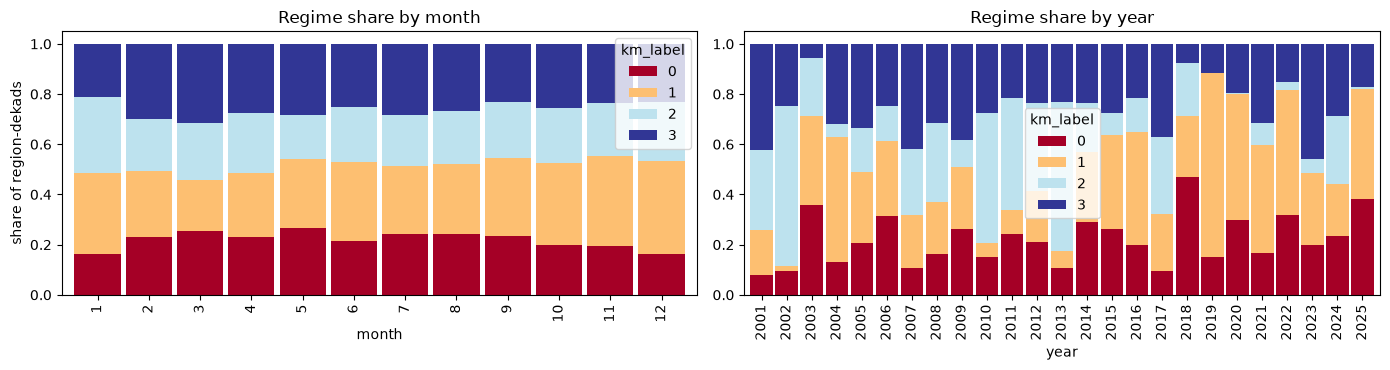

In [61]:
def profile(df, label_col, feat_cols):
    k = df[label_col].nunique()
    prof = df.groupby(label_col)[feat_cols].mean()
    size = df[label_col].value_counts(normalize=True).sort_index().rename("share")

    # run lengths per regime (consecutive dekads in the same regime within one region)
    runs = {lab: [] for lab in range(k)}
    for _, g in df.groupby("region_id"):
        s = g[label_col].values
        change = np.flatnonzero(np.diff(s) != 0) + 1
        for a, b in zip(np.r_[0, change], np.r_[change, len(s)]):
            runs[s[a]].append(b - a)
    run_mean = pd.Series({l: np.mean(r) for l, r in runs.items()}, name="mean_run_dekads")
    run_med = pd.Series({l: np.median(r) for l, r in runs.items()}, name="median_run_dekads")

    return prof, pd.concat([size, run_mean, run_med], axis=1)

prof_km, info_km = profile(ml_df, "km_label", feat_cols)
print(info_km.round(2)); print(prof_km.round(2))

# 1) feature-mean heatmap
fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(prof_km, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(feat_cols)), feat_cols, rotation=45, ha="right")
ax.set_yticks(range(K), [f"R{i} ({info_km.loc[i,'share']:.0%})" for i in range(K)])
for i in range(K):
    for j in range(len(feat_cols)):
        ax.text(j, i, f"{prof_km.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, shrink=0.8); ax.set_title("K-means regime profiles (mean z-score)")
plt.tight_layout(); plt.show()

# 2) seasonality: share of each regime per month
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
season = pd.crosstab(ml_df["month"], ml_df["km_label"], normalize="index")
season.plot(kind="bar", stacked=True, ax=axes[0], colormap="RdYlBu", width=0.9)
axes[0].set_title("Regime share by month"); axes[0].set_ylabel("share of region-dekads")

# 3) the key plot: share of each regime per year
yearly = pd.crosstab(ml_df["year"], ml_df["km_label"], normalize="index")
yearly.plot(kind="bar", stacked=True, ax=axes[1], colormap="RdYlBu", width=0.9)
axes[1].set_title("Regime share by year")
plt.tight_layout(); plt.show()

In [62]:
#K-Mean VS GMM
ct = pd.crosstab(ml_df["km_label"], ml_df["gmm_label"])
r, c = linear_sum_assignment(-ct.values)          # best one-to-one matching of regimes
ct_aligned = ct.iloc[:, c]
agreement = np.trace(ct_aligned.values) / ct.values.sum()

print("ARI KM vs GMM:", round(adjusted_rand_score(ml_df["km_label"], ml_df["gmm_label"]), 3))
print(f"Agreement after optimal matching: {agreement:.1%}")
print(ct_aligned)

print("\nGMM profiles:")
prof_gmm, info_gmm = profile(ml_df, "gmm_label", feat_cols)
print(info_gmm.round(2)); print(prof_gmm.round(2))

# how soft is the GMM? mean max posterior and share of ambiguous rows
print("\nmean max posterior per GMM regime:\n", ml_df.groupby("gmm_label")["gmm_maxprob"].mean().round(2))
print("share of rows with max posterior < 0.6:", round((ml_df["gmm_maxprob"] < 0.6).mean(), 3))

# where the two methods differ: feature profile of disagreement rows
ml_df["agree"] = ml_df["km_label"].map(dict(zip(ct.index, ct.index[np.argsort(c)]))) == ml_df["gmm_label"]

ARI KM vs GMM: 0.346
Agreement after optimal matching: 67.3%
gmm_label      0      1     2      3
km_label                            
0          12068   1599  1910      3
1           1764  13050  2832   3320
2           2261   1767  7201   4510
3              6   2752   480  15340

GMM profiles:
   share  mean_run_dekads  median_run_dekads
0   0.23             1.47                1.0
1   0.27             1.82                1.0
2   0.18             1.51                1.0
3   0.33             1.73                1.0
           pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  \
gmm_label                                                                    
0         -1.43     -0.83       1.18   0.19   0.75    -0.72          -0.78   
1          0.10      0.04       0.06   0.07   0.15    -0.35           0.15   
2          0.07     -0.17       0.15  -0.10   0.04     0.03          -0.42   
3          0.88      0.64      -0.95  -0.13  -0.66     0.79           0.64   

        

In [ ]:
# print out number of regime share by year 
yr = pd.crosstab(ml_df["year"], ml_df["km_label"], normalize="index").round(2)
print(yr)    # look at the R0 and R1 columns

km_label     0     1     2     3
year                            
2001      0.08  0.18  0.32  0.42
2002      0.10  0.02  0.64  0.25
2003      0.36  0.36  0.23  0.05
2004      0.13  0.50  0.05  0.32
2005      0.20  0.28  0.18  0.34
2006      0.31  0.30  0.14  0.25
2007      0.11  0.21  0.27  0.42
2008      0.16  0.21  0.32  0.31
2009      0.26  0.24  0.11  0.38
2010      0.15  0.05  0.52  0.27
2011      0.24  0.09  0.45  0.22
2012      0.21  0.20  0.35  0.24
2013      0.11  0.07  0.60  0.23
2014      0.29  0.28  0.19  0.24
2015      0.26  0.38  0.09  0.28
2016      0.20  0.45  0.14  0.21
2017      0.09  0.23  0.31  0.37
2018      0.47  0.25  0.21  0.08
2019      0.15  0.73  0.00  0.12
2020      0.30  0.50  0.00  0.20
2021      0.17  0.43  0.09  0.32
2022      0.32  0.50  0.03  0.15
2023      0.20  0.29  0.05  0.46
2024      0.23  0.21  0.27  0.29
2025      0.38  0.44  0.01  0.17


### K = 5

In [65]:
# persistence diagnostics: lag-1 autocorrelation of each feature (mean over regions)
ac = {f: ml_df.groupby("region_id")[f].apply(lambda s: s.autocorr(1)).mean() for f in feat_cols}
print(pd.Series(ac).round(2))        # expect ~0.9 for smmid/smlow, ~0 for pr_z

# k sensitivity (K-means only, fast)
for k in (3, 4, 5):
    km_k = KMeans(n_clusters=k, n_init=50, random_state=42).fit(Xs)
    ml_df[f"km_label_k{k}"] = reorder_by_wetness(km_k.labels_, ml_df)
    prof, info = profile(ml_df, f"km_label_k{k}", feat_cols)
    print(f"k={k}"); print(info.round(2)); print(prof.round(2))

pr_z             0.09
pr3dek_z         0.63
drydays_z        0.10
tas_z            0.33
dtr_z            0.25
smtop_z          0.67
smtop_trend_z    0.51
smmid_z          0.98
smlow_z          0.99
dtype: float64
k=3
   share  mean_run_dekads  median_run_dekads
0   0.38             2.53                2.0
1   0.36             2.41                2.0
2   0.25             2.73                2.0
             pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  \
km_label_k3                                                                    
0           -0.79     -0.80       0.77   0.29   0.69    -0.87          -0.64   
1            0.74      0.65      -0.80  -0.13  -0.52     0.61           0.81   
2            0.14      0.27      -0.02  -0.24  -0.29     0.45          -0.19   

             smmid_z  smlow_z  
km_label_k3                    
0              -0.37    -0.25  
1              -0.33    -0.39  
2               1.04     0.95  
k=4
   share  mean_run_dekads  median_run_

In [66]:
K = 5

# profiling and run lengths need chronological order within each region
ml_df = ml_df.sort_values(["region_id", "year", "month", "dekad"]).reset_index(drop=True)
assert len(ml_df) == len(Xs), "ml_df and Xs must have the same row order, rebuild Xs/Z6 from the sorted frame"

def reorder_by_wetness(labels, df, cols=("pr3dek_z", "smtop_z", "smmid_z")):
    """Relabel clusters so 0 = driest ... k-1 = wettest (mean of the three wetness features)."""
    wet = df[list(cols)].mean(axis=1).values
    order = pd.Series(wet).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[l] for l in labels])

def fit_models(X, k, df, seed=42):
    km = KMeans(n_clusters=k, n_init=50, random_state=seed).fit(X)
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=20,
                          max_iter=500, random_state=seed).fit(X)
    print(f"GMM converged: {gmm.converged_}, log-likelihood lower bound: {gmm.lower_bound_:.4f}")
    km_lab = reorder_by_wetness(km.labels_, df)
    gmm_lab = reorder_by_wetness(gmm.predict(X), df)
    return km, gmm, km_lab, gmm_lab

km9, gmm9, ml_df["km_label"], ml_df["gmm_label"] = fit_models(Xs, K, ml_df)
km6, gmm6, ml_df["km_label_pc"], ml_df["gmm_label_pc"] = fit_models(Z6, K, ml_df)

# GMM posterior: how "soft" is the assignment?
post = gmm9.predict_proba(Xs)
ml_df["gmm_maxprob"] = post.max(axis=1)

# robustness: 9 features vs 6 PCs
print("ARI KM 9feat vs 6PC :", round(adjusted_rand_score(ml_df["km_label"], ml_df["km_label_pc"]), 3))
print("ARI GMM 9feat vs 6PC:", round(adjusted_rand_score(ml_df["gmm_label"], ml_df["gmm_label_pc"]), 3))

GMM converged: True, log-likelihood lower bound: -9.7311
GMM converged: True, log-likelihood lower bound: -8.5500
ARI KM 9feat vs 6PC : 0.949
ARI GMM 9feat vs 6PC: 0.239


   share  mean_run_dekads  median_run_dekads
0   0.16             1.59                1.0
1   0.22             1.92                1.0
2   0.23             1.95                1.0
3   0.25             2.01                1.0
4   0.14             2.33                2.0
          pr_z  pr3dek_z  drydays_z  tas_z  dtr_z  smtop_z  smtop_trend_z  \
km_label                                                                    
0        -1.41     -1.37       1.16   0.43   1.07    -1.09          -1.05   
1        -0.14     -0.30       0.30   0.26   0.40    -0.70          -0.18   
2        -0.25     -0.06       0.35  -0.22  -0.08     0.03          -0.40   
3         0.76      0.63      -0.82  -0.08  -0.50     0.57           0.83   
4         0.89      1.01      -0.90  -0.38  -0.81     1.31           0.64   

          smmid_z  smlow_z  
km_label                    
0           -0.07     0.10  
1           -0.84    -0.75  
2            0.71     0.68  
3           -0.48    -0.51  
4            1.1

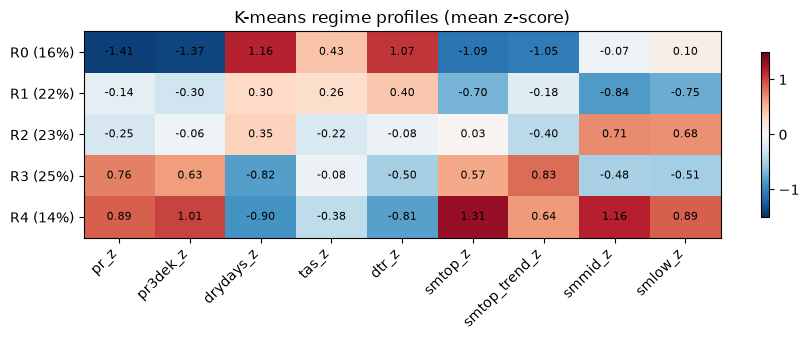

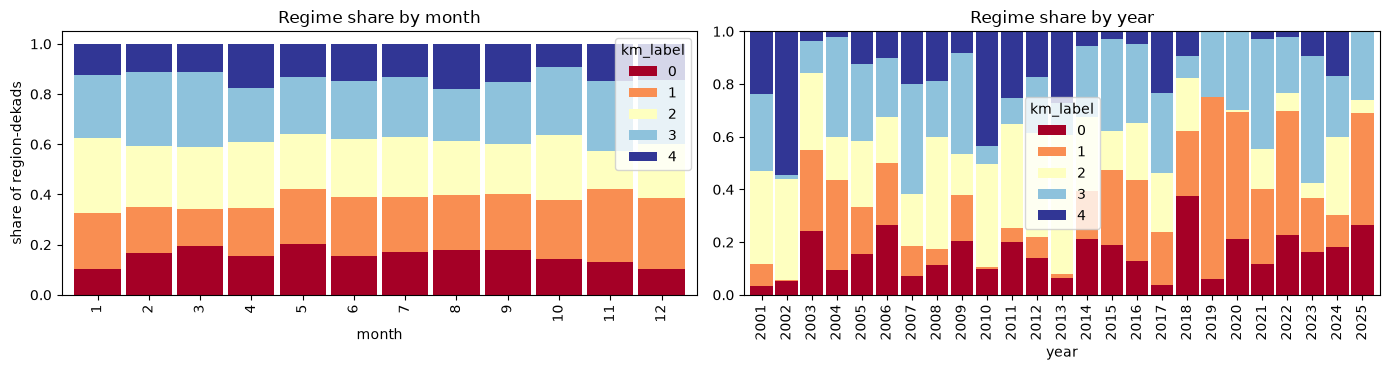

In [67]:
def profile(df, label_col, feat_cols):
    k = df[label_col].nunique()
    prof = df.groupby(label_col)[feat_cols].mean()
    size = df[label_col].value_counts(normalize=True).sort_index().rename("share")

    # run lengths per regime (consecutive dekads in the same regime within one region)
    runs = {lab: [] for lab in range(k)}
    for _, g in df.groupby("region_id"):
        s = g[label_col].values
        change = np.flatnonzero(np.diff(s) != 0) + 1
        for a, b in zip(np.r_[0, change], np.r_[change, len(s)]):
            runs[s[a]].append(b - a)
    run_mean = pd.Series({l: np.mean(r) for l, r in runs.items()}, name="mean_run_dekads")
    run_med = pd.Series({l: np.median(r) for l, r in runs.items()}, name="median_run_dekads")

    return prof, pd.concat([size, run_mean, run_med], axis=1)

prof_km, info_km = profile(ml_df, "km_label", feat_cols)
print(info_km.round(2)); print(prof_km.round(2))

# 1) feature-mean heatmap
fig, ax = plt.subplots(figsize=(9, 3.5))
im = ax.imshow(prof_km, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(feat_cols)), feat_cols, rotation=45, ha="right")
ax.set_yticks(range(K), [f"R{i} ({info_km.loc[i,'share']:.0%})" for i in range(K)])
for i in range(K):
    for j in range(len(feat_cols)):
        ax.text(j, i, f"{prof_km.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, shrink=0.8); ax.set_title("K-means regime profiles (mean z-score)")
plt.tight_layout(); plt.show()

# 2) seasonality: share of each regime per month
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
season = pd.crosstab(ml_df["month"], ml_df["km_label"], normalize="index")
season.plot(kind="bar", stacked=True, ax=axes[0], colormap="RdYlBu", width=0.9)
axes[0].set_title("Regime share by month"); axes[0].set_ylabel("share of region-dekads")

# 3) the key plot: share of each regime per year
yearly = pd.crosstab(ml_df["year"], ml_df["km_label"], normalize="index")
yearly.plot(kind="bar", stacked=True, ax=axes[1], colormap="RdYlBu", width=0.9)
axes[1].set_title("Regime share by year")
plt.tight_layout(); plt.show()

In [69]:
def transition_matrix(df, label_col):
    k = df[label_col].nunique()
    T = np.zeros((k, k))
    for _, g in df.groupby("region_id"):      # df is sorted by region, year, month, dekad
        s = g[label_col].values
        np.add.at(T, (s[:-1], s[1:]), 1)
    return pd.DataFrame(T / T.sum(axis=1, keepdims=True),
                        index=[f"from R{i}" for i in range(k)],
                        columns=[f"to R{i}" for i in range(k)]).round(2)

print(transition_matrix(ml_df, "km_label_k5"))

         to R0  to R1  to R2  to R3  to R4
from R0   0.37   0.31   0.17   0.12   0.03
from R1   0.16   0.48   0.02   0.34   0.00
from R2   0.18   0.04   0.49   0.12   0.17
from R3   0.07   0.23   0.14   0.50   0.06
from R4   0.03   0.00   0.38   0.02   0.57


In [68]:
labs = [reorder_by_wetness(GaussianMixture(5, covariance_type="full", n_init=20, max_iter=500,
                                           random_state=s).fit(Xs).predict(Xs), ml_df) for s in (1, 2, 3)]
print([round(adjusted_rand_score(labs[i], labs[j]), 2) for i, j in [(0, 1), (0, 2), (1, 2)]])

[0.8, 0.79, 0.94]


In [72]:
# find best fit for GMM (for K-Means it is k=5, but this is not that stable for GMM)
fits = []
for s in range(10):
    g = GaussianMixture(5, covariance_type="full", n_init=10, max_iter=1000, random_state=s).fit(Xs)
    fits.append((g.score(Xs), s, g))
fits.sort(key=lambda t: -t[0])
print([(round(sc, 4), s) for sc, s, _ in fits])    # mean log-likelihood per row

gmm5_lab = reorder_by_wetness(fits[0][2].predict(Xs), ml_df)
for sc, s, g in fits[1:]:
    print(s, round(adjusted_rand_score(gmm5_lab, reorder_by_wetness(g.predict(Xs), ml_df)), 2))

[(-9.7303, 7), (-9.7303, 1), (-9.7306, 8), (-9.7308, 9), (-9.7308, 0), (-9.7309, 3), (-9.7309, 5), (-9.7309, 4), (-9.731, 6), (-9.7312, 2)]
1 0.98
8 0.79
9 0.78
0 0.78
3 0.78
5 0.95
4 0.78
6 0.96
2 0.95


In [ ]:
# try removing drydays_z from feature set
Xs8 = StandardScaler().fit_transform(ml_df[feat_cols].drop(columns="drydays_z"))
lab8 = reorder_by_wetness(KMeans(5, n_init=50, random_state=42).fit(Xs8).labels_, ml_df)
print("ARI 9 vs 8 features:", round(adjusted_rand_score(ml_df["km_label_k5"], lab8), 3))

ARI 9 vs 8 features: 0.735


In [74]:
# which regimes changed, when removing drydays_z?
ml_df["km_label_k5_8f"] = lab8

ct = pd.crosstab(ml_df["km_label_k5"], ml_df["km_label_k5_8f"])
r, c = linear_sum_assignment(-ct.values)
print(f"Agreement after optimal matching: {ct.values[r, c].sum() / ct.values.sum():.1%}")
print(ct)
print(ct.div(ct.sum(axis=1), axis=0).round(2))     # where does each 9-feature regime go?

feat8 = [f for f in feat_cols if f != "drydays_z"]
prof8, info8 = profile(ml_df, "km_label_k5_8f", feat8)
print(info8.round(2)); print(prof8.round(2))

# context: how much does the 6-PC representation change k=5?
km5_pc = KMeans(5, n_init=50, random_state=42).fit(Z6)
print("ARI 9 features vs 6 PCs (k=5):", round(adjusted_rand_score(ml_df["km_label_k5"], km5_pc.labels_), 3))

Agreement after optimal matching: 88.8%
km_label_k5_8f     0      1      2      3     4
km_label_k5                                    
0               9680    511    904      0     0
1                383  14098    593    707     0
2                 58      0  14551    781  1014
3                  0   1076    918  15837    13
4                  0      0    333    623  8783
km_label_k5_8f     0     1     2     3     4
km_label_k5                                 
0               0.87  0.05  0.08  0.00  0.00
1               0.02  0.89  0.04  0.04  0.00
2               0.00  0.00  0.89  0.05  0.06
3               0.00  0.06  0.05  0.89  0.00
4               0.00  0.00  0.03  0.06  0.90
   share  mean_run_dekads  median_run_dekads
0   0.14             1.65                1.0
1   0.22             2.11                1.0
2   0.24             2.09                1.0
3   0.25             2.27                2.0
4   0.14             2.66                2.0
                pr_z  pr3dek_z  tas_z  

In [76]:
def plot_regime_overview(df, label_col, title, feat_cols):
    """Profile table, feature-mean heatmap, and regime shares by month and by year."""
    k = df[label_col].nunique()
    prof, info = profile(df, label_col, feat_cols)
    print(f"--- {title} ---")
    print(info.round(2)); print(prof.round(2))

    fig, ax = plt.subplots(figsize=(9, 3.5))
    im = ax.imshow(prof, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(len(feat_cols)), feat_cols, rotation=45, ha="right")
    ax.set_yticks(range(k), [f"R{i} ({info.loc[i, 'share']:.0%})" for i in range(k)])
    for i in range(k):
        for j in range(len(feat_cols)):
            ax.text(j, i, f"{prof.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, shrink=0.8)
    ax.set_title(f"{title} regime profiles (mean z-score)")
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    pd.crosstab(df["month"], df[label_col], normalize="index").plot(
        kind="bar", stacked=True, ax=axes[0], colormap="RdYlBu", width=0.9)
    axes[0].set_title(f"{title}: regime share by month")
    pd.crosstab(df["year"], df[label_col], normalize="index").plot(
        kind="bar", stacked=True, ax=axes[1], colormap="RdYlBu", width=0.9)
    axes[1].set_title(f"{title}: regime share by year")
    plt.tight_layout(); plt.show()
    return prof, info

ARI KM vs GMM (k=5): 0.219
Agreement after optimal matching: 51.4%
gmm_label_k5     0     1     2      3     4
km_label_k5                                
0             8041   172  2734     71    77
1             1655  3464  7223   3414    25
2             2992   774  8264   3695   679
3                3  2852  1006  13775   208
4                1    90   739   6003  2906
gmm_label_k5     0     1     2     3     4
km_label_k5                               
0             0.72  0.02  0.25  0.01  0.01
1             0.10  0.22  0.46  0.22  0.00
2             0.18  0.05  0.50  0.23  0.04
3             0.00  0.16  0.06  0.77  0.01
4             0.00  0.01  0.08  0.62  0.30
--- GMM k=5 (aligned) ---
   share  mean_run_dekads  median_run_dekads
0   0.18             1.37                1.0
1   0.10             1.51                1.0
2   0.28             1.47                1.0
3   0.38             1.84                1.0
4   0.05             1.76                1.0
                 pr_z  pr3de

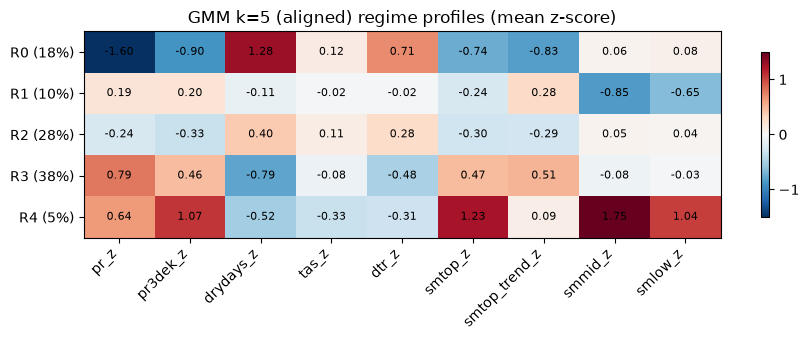

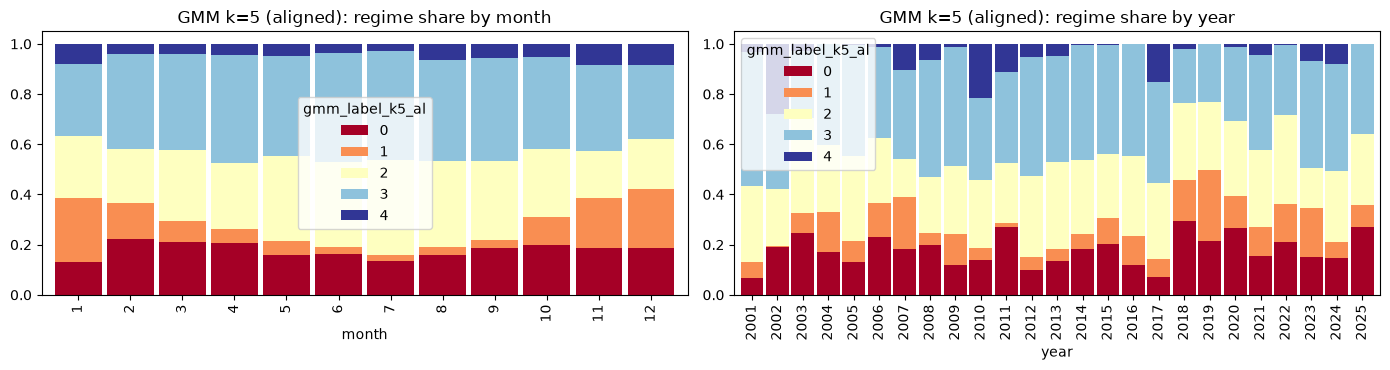

gmm_label_k5_al
0    0.88
1    0.74
2    0.72
3    0.80
4    0.77
Name: gmm5_maxprob, dtype: float64
share with max posterior < 0.6: 0.199
GMM component weights: [0.27 0.35 0.18 0.06 0.13]


In [77]:
# compare K-means and GMM at k=5
gmm5 = fits[0][2]                                   # best-likelihood fit (seed 7)
ml_df["gmm_label_k5"] = reorder_by_wetness(gmm5.predict(Xs), ml_df)
ml_df["gmm5_maxprob"] = gmm5.predict_proba(Xs).max(axis=1)

ct = pd.crosstab(ml_df["km_label_k5"], ml_df["gmm_label_k5"])
r, c = linear_sum_assignment(-ct.values)
print("ARI KM vs GMM (k=5):", round(adjusted_rand_score(ml_df["km_label_k5"], ml_df["gmm_label_k5"]), 3))
print(f"Agreement after optimal matching: {ct.values[r, c].sum() / ct.values.sum():.1%}")
print(ct); print(ct.div(ct.sum(axis=1), axis=0).round(2))

# the wetness ordering can differ between methods, so align GMM labels to K-means for plotting
mapping = {ct.columns[cj]: ct.index[ri] for ri, cj in zip(r, c)}
ml_df["gmm_label_k5_al"] = ml_df["gmm_label_k5"].map(mapping)
prof_g5, info_g5 = plot_regime_overview(ml_df, "gmm_label_k5_al", "GMM k=5 (aligned)", feat_cols)

print(ml_df.groupby("gmm_label_k5_al")["gmm5_maxprob"].mean().round(2))
print("share with max posterior < 0.6:", round((ml_df["gmm5_maxprob"] < 0.6).mean(), 3))
print("GMM component weights:", np.round(gmm5.weights_, 2))

In [78]:
print("GMM component shares:", ml_df["gmm_label_k5"].value_counts(normalize=True).sort_index().round(3).values)
print("within-regime spread (mean std over features):")
print(pd.DataFrame({
    "kmeans": ml_df.groupby("km_label_k5")[feat_cols].std().mean(axis=1),
    "gmm":    ml_df.groupby("gmm_label_k5")[feat_cols].std().mean(axis=1),
}).round(2))

GMM component shares: [0.179 0.104 0.282 0.38  0.055]
within-regime spread (mean std over features):
   kmeans   gmm
0    0.77  0.87
1    0.72  0.87
2    0.74  0.79
3    0.68  0.77
4    0.74  0.88
